<a href="https://colab.research.google.com/github/jinho1017-eng/Korean-movie-ml/blob/main/%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D_(_%ED%95%9C%EA%B5%AD_%EC%98%81%ED%99%94_%ED%86%B5%EA%B3%84).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. 데이터 불러오기**

In [ ]:
import pandas as pd

df = pd.read_csv('/movie_box_office_kr_until_2025_0430.csv')

df.head()

,rank,title,director,release_date,movie_type,format_type,nation,screens_total,sales_total_krw,audience_total,sales_seoul_krw,audience_seoul,genre,rating,film_class
0,1,Myeongryang,Kim Han-min,2014-07-30,Theatrical Release,Feature,KR,1587,135748398910,17613682,3.312123e+10,4163666,Historical,15+,Commercial
1,2,Extreme Job,Lee Byung-hun,2019-01-23,Theatrical Release,Feature,KR,1978,139647979516,16264944,3.185866e+10,3638287,Comedy,15+,Commercial
2,3,Along with the Gods: The Two Worlds,Kim Yong-hwa,2017-12-20,Theatrical Release,Feature,KR,1912,115698654137,14410754,2.753083e+10,3346172,Fantasy,12+,Commercial
3,4,International Market,Yoon Je-gyun,2014-12-17,Theatrical Release,Feature,KR,966,110828014630,14245998,2.584252e+10,3233946,Drama,12+,Commercial
4,5,Avengers: Endgame,"Anthony Russo, Joe Russo",2019-04-24,Theatrical Release,Feature,US,2835,122182694160,13934592,3.357714e+10,3597963,Action,12+,Commercial


**2. 데이터 크기 확인**

In [ ]:
df.shape

(20730, 15)

**3. 컬럼명 확인**

In [ ]:
df.columns

Index(['rank', 'title', 'director', 'release_date', 'movie_type',
       'format_type', 'nation', 'screens_total', 'sales_total_krw',
       'audience_total', 'sales_seoul_krw', 'audience_seoul', 'genre',
       'rating', 'film_class'],
      dtype='object')

**4. 데이터 타입 확인**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20730 entries, 0 to 20729
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rank             20730 non-null  int64  
 1   title            20730 non-null  object 
 2   director         20730 non-null  object 
 3   release_date     20730 non-null  object 
 4   movie_type       20730 non-null  object 
 5   format_type      20730 non-null  object 
 6   nation           20730 non-null  object 
 7   screens_total    20730 non-null  int64  
 8   sales_total_krw  20730 non-null  int64  
 9   audience_total   20730 non-null  int64  
 10  sales_seoul_krw  20723 non-null  float64
 11  audience_seoul   20730 non-null  int64  
 12  genre            20730 non-null  object 
 13  rating           20730 non-null  object 
 14  film_class       20730 non-null  object 
dtypes: float64(1), int64(5), object(9)
memory usage: 2.4+ MB


**5. 결측값 확인 **

In [ ]:
df.isnull().sum()

,0
rank,0
title,0
director,0
release_date,0
movie_type,0
format_type,0
nation,0
screens_total,0
sales_total_krw,0
audience_total,0


**6. 결측값 처리**


In [ ]:
df = df.dropna(subset=['sales_seoul_krw', 'film_class'])
df.isnull().sum()
df.shape

(20723, 15)

**7. 제외할 변수 제거**

In [ ]:
df = df.drop(columns=['rank', 'title', 'director', 'sales_total_krw', 'movie_type'], errors='ignore')

df.columns

Index(['release_date', 'format_type', 'nation', 'screens_total',
       'audience_total', 'sales_seoul_krw', 'audience_seoul', 'genre',
       'rating', 'film_class'],
      dtype='object')

**8. 날짜 변수 변환**

In [ ]:

df.columns = df.columns.str.strip()

if 'release_date' in df.columns:
    df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

    df['release_year'] = df['release_date'].dt.year
    df['release_month'] = df['release_date'].dt.month

    df = df.drop(columns=['release_date'])

    print("release_date 변환 완료")
else:
    print("release_date 컬럼이 없습니다. 이미 변환되었거나 삭제된 상태입니다.")

df.head()

release_date 변환 완료


,format_type,nation,screens_total,audience_total,sales_seoul_krw,audience_seoul,genre,rating,film_class,release_year,release_month
0,Feature,KR,1587,17613682,3.312123e+10,4163666,Historical,15+,Commercial,2014,7
1,Feature,KR,1978,16264944,3.185866e+10,3638287,Comedy,15+,Commercial,2019,1
2,Feature,KR,1912,14410754,2.753083e+10,3346172,Fantasy,12+,Commercial,2017,12
3,Feature,KR,966,14245998,2.584252e+10,3233946,Drama,12+,Commercial,2014,12
4,Feature,US,2835,13934592,3.357714e+10,3597963,Action,12+,Commercial,2019,4


**9. 목표 변수와 입력 변수 분리**

In [ ]:
X = df.drop(columns=['audience_total'])
y = df['audience_total']

print(X.shape)
print(y.shape)

(20723, 10)
(20723,)


**10. 범주형 변수 인코딩**

In [ ]:
X = pd.get_dummies(X, drop_first=True)

X.head()
X.shape

(20723, 103)

**11. 학습/테스트 데이터 분리**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16578, 103)
(4145, 103)
(16578,)
(4145,)


**2-1. 수치형 변수 기본 통계 확인 **

In [ ]:
df[['screens_total', 'audience_total', 'sales_seoul_krw', 'audience_seoul']].describe()

,screens_total,audience_total,sales_seoul_krw,audience_seoul
count,20723.000000,2.072300e+04,2.072300e+04,2.072300e+04
mean,86.610240,1.203239e+05,2.803234e+08,3.251309e+04
std,241.998682,7.242068e+05,1.627458e+09,1.870043e+05
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.000000,1.000000e+00,0.000000e+00,0.000000e+00
50%,1.000000,5.400000e+01,1.000000e+05,2.000000e+01
75%,33.000000,3.861000e+03,1.631965e+07,1.943000e+03
max,2980.000000,1.761368e+07,3.547671e+10,4.163666e+06


**2-2. 전체 관객 수 분포 확인**

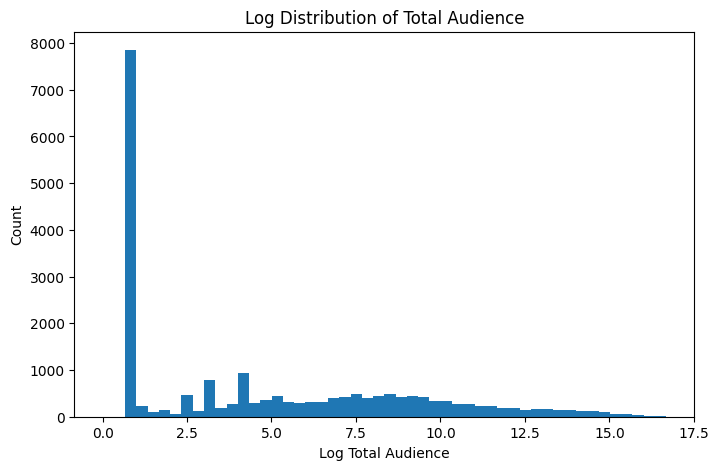

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(np.log1p(df['audience_total']), bins=50)
plt.title('Log Distribution of Total Audience')
plt.xlabel('Log Total Audience')
plt.ylabel('Count')
plt.show()

**2-3. 전체 스크린 수와 전체 관객 수 관계 확인**

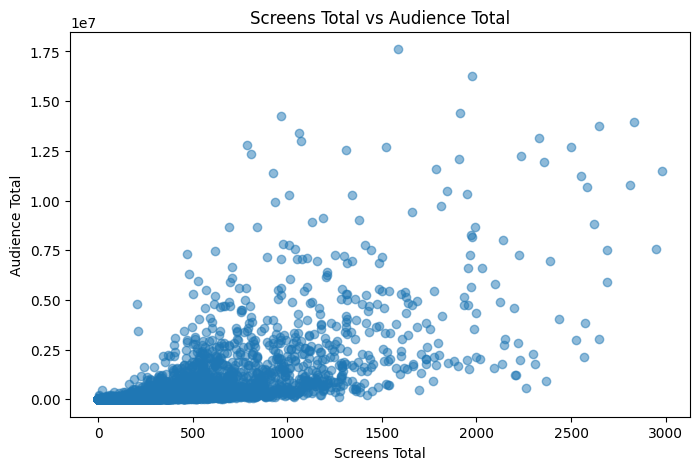

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df['screens_total'], df['audience_total'], alpha=0.5)
plt.title('Screens Total vs Audience Total')
plt.xlabel('Screens Total')
plt.ylabel('Audience Total')
plt.show()

**2-4. 서울 관객수와 전체 관객 수 관계확인**

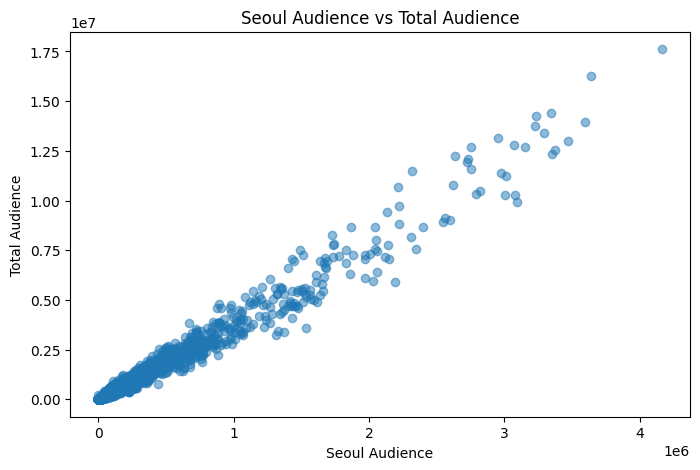

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df['audience_seoul'], df['audience_total'], alpha=0.5)
plt.title('Seoul Audience vs Total Audience')
plt.xlabel('Seoul Audience')
plt.ylabel('Total Audience')
plt.show()

**2-5. 장르별 평균 관객 수 비교**

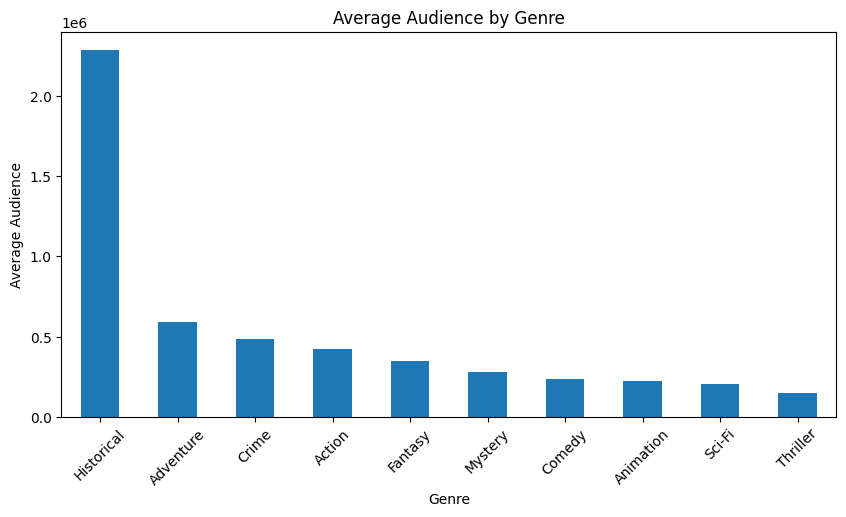

In [ ]:
genre_audience = df.groupby('genre')['audience_total'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
genre_audience.plot(kind='bar')
plt.title('Average Audience by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Audience')
plt.xticks(rotation=45)
plt.show()

**2-6. 관람 등급별 평균 관객 수 비교**

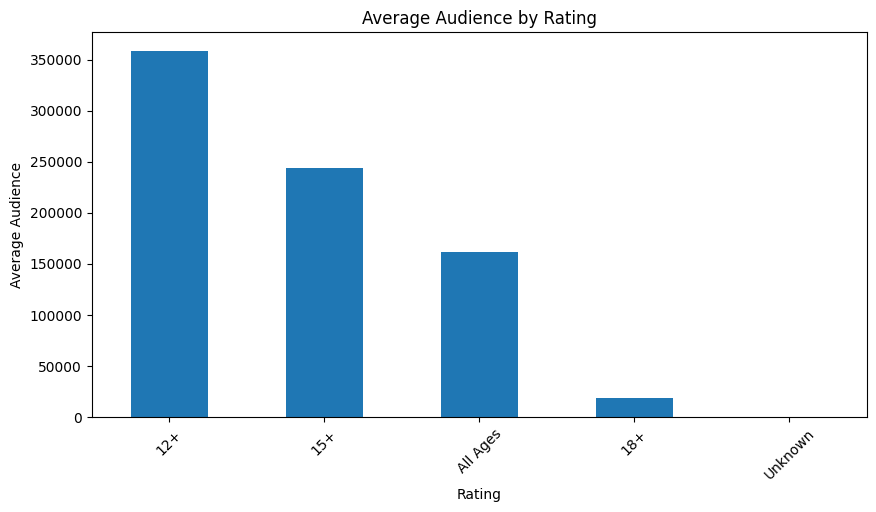

In [ ]:
rating_audience = df.groupby('rating')['audience_total'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,5))
rating_audience.plot(kind='bar')
plt.title('Average Audience by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Audience')
plt.xticks(rotation=45)
plt.show()

**2-7. 수치형 변수 간 상관관계**

In [ ]:
corr = df[['screens_total', 'audience_total', 'sales_seoul_krw', 'audience_seoul']].corr()
corr

,screens_total,audience_total,sales_seoul_krw,audience_seoul
screens_total,1.000000,0.692303,0.705941,0.685071
audience_total,0.692303,1.000000,0.983709,0.989055
sales_seoul_krw,0.705941,0.983709,1.000000,0.992806
audience_seoul,0.685071,0.989055,0.992806,1.000000


**3-1. 모델 학습 준비**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

**모델 객체 생성**

In [ ]:
linear_model = LinearRegression()
tree_model = DecisionTreeRegressor(random_state=42)
forest_model = RandomForestRegressor(random_state=42)

**모델 학습**

In [ ]:
linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

**테스트 데이터 예측**

In [ ]:
linear_pred = linear_model.predict(X_test)
tree_pred = tree_model.predict(X_test)
forest_pred = forest_model.predict(X_test)

**하이퍼파라미터 튜닝**

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_model = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_model.fit(X_train, y_train)

print(grid_model.best_params_)
print(grid_model.best_score_)

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
-15828.481643224106


In [ ]:
best_forest_model = grid_model.best_estimator_

best_forest_pred = best_forest_model.predict(X_test)

**튜닝된 랜덤포레스트 모델**

In [ ]:
compare_df = pd.DataFrame({
    '실제 관객 수': y_test.values,
    '예측 관객 수': best_forest_pred
})

compare_df.head(10)

,실제 관객 수,예측 관객 수
0,1,1.053082
1,2,30.677500
2,2881,3556.540000
3,1,1.000000
4,1,1.042153
5,212154,185266.140000
6,60,60.000000
7,1,1.370000
8,32,11.600000
9,1,1.180000


**평가 지표 불러오기**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

**모델별 성능 계산**

In [ ]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))
tree_r2 = r2_score(y_test, tree_pred)

forest_mae = mean_absolute_error(y_test, forest_pred)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_pred))
forest_r2 = r2_score(y_test, forest_pred)


모델 성능 비교표

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_forest_mae = mean_absolute_error(y_test, best_forest_pred)
best_forest_rmse = np.sqrt(mean_squared_error(y_test, best_forest_pred))
best_forest_r2 = r2_score(y_test, best_forest_pred)

print("튜닝된 랜덤포레스트 MAE:", best_forest_mae)
print("튜닝된 랜덤포레스트 RMSE:", best_forest_rmse)
print("튜닝된 랜덤포레스트 R2:", best_forest_r2)

튜닝된 랜덤포레스트 MAE: 13360.279545547253
튜닝된 랜덤포레스트 RMSE: 77879.1238410775
튜닝된 랜덤포레스트 R2: 0.9875213853242084


In [ ]:
import pandas as pd

result_df = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Tuned Random Forest'
    ],
    'MAE': [
        linear_mae,
        tree_mae,
        forest_mae,
        best_forest_mae
    ],
    'RMSE': [
        linear_rmse,
        tree_rmse,
        forest_rmse,
        best_forest_rmse
    ],
    'R2': [
        linear_r2,
        tree_r2,
        forest_r2,
        best_forest_r2
    ]
})

result_df

,Model,MAE,RMSE,R2
0,Linear Regression,28991.867343,98836.626373,0.979902
1,Decision Tree,17275.536562,106413.945803,0.976702
2,Random Forest,13360.279546,77879.123841,0.987521
3,Tuned Random Forest,13360.279546,77879.123841,0.987521


**모델 성능 비교 그래프**

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
bars = plt.bar(result_df['Model'], result_df['R2'])

plt.title('Model Comparison by R2')
plt.xlabel('Model')
plt.ylabel('R2 Score')
plt.ylim(result_df['R2'].min() - 0.002, result_df['R2'].max() + 0.002)
plt.xticks(rotation=30)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.0002,
        f'{height:.6f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.show()